# Redrob Candidate Pool — EDA

Exploratory analysis of `candidates.jsonl` (100,000 candidates) for the **Senior AI Engineer — Founding Team** ranking task.

Goals of this notebook:
1. Understand the schema and field distributions.
2. Profile the 23 `redrob_signals` behavioral signals, quantifying the `-1` *no-data* sentinel per signal.
3. Build a **title-vs-skills coherence** feature to separate genuine fits from keyword stuffers.
4. Treat honeypot detection as a **precision gate on the top of the ranking**, not a pool-wide classifier.

All recency / tenure / date math is anchored to a data-derived `REF_DATE` (not the wall clock) so the notebook — and the ranker built from it — is deterministic and reproducible for the Stage-3 check.

See the `.docx` docs in the bundle for the full task framing.

## 1. Setup & load

The full file is ~487 MB uncompressed. Parsing all 100K records as dicts is fine on 16 GB RAM. We flatten the scalar fields into a DataFrame for fast slicing and keep the raw records around for nested inspection (career history, skills).

In [14]:
import json
import re
from collections import Counter
from datetime import date, datetime

import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

PATH = "candidates.jsonl"

records = []
with open(PATH, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            records.append(json.loads(line))

print(f"Loaded {len(records):,} candidates")
print("Top-level keys:", list(records[0].keys()))

Loaded 100,000 candidates
Top-level keys: ['candidate_id', 'profile', 'career_history', 'education', 'skills', 'certifications', 'languages', 'redrob_signals']


In [15]:
# Reproducibility anchor. Derive a fixed "now" from the data instead of date.today().
# Every recency / tenure / future-date check below uses REF_DATE, so the same input
# always produces the same output. The Stage-3 reproduction depends on this determinism;
# a hardcoded calendar date silently shifts every result when the judges (or you) re-run.
_active = pd.to_datetime([c["redrob_signals"].get("last_active_date") for c in records], errors="coerce")
REF_DATE = _active.max()
by_id = {c["candidate_id"]: c for c in records}
print("REF_DATE (max last_active_date in pool):", REF_DATE.date())

REF_DATE (max last_active_date in pool): 2026-05-27


In [16]:
# Flatten profile + redrob_signals SCALARS into a DataFrame for fast slicing.
# Nested detail (career_history, skills) is intentionally NOT flattened here -- it is
# needed in full for the coherence and honeypot features below, where the count alone
# (e.g. n_skills) throws away exactly the quality signal that catches stuffers.
# Use `by_id[candidate_id]` to reach the raw nested record anywhere downstream.
def flatten(c):
    p = c.get("profile", {})
    s = c.get("redrob_signals", {})
    sal = s.get("expected_salary_range_inr_lpa", {}) or {}
    row = {
        "candidate_id": c["candidate_id"],
        "headline": p.get("headline"),
        "current_title": p.get("current_title"),
        "current_company": p.get("current_company"),
        "current_company_size": p.get("current_company_size"),
        "current_industry": p.get("current_industry"),
        "location": p.get("location"),
        "country": p.get("country"),
        "years_of_experience": p.get("years_of_experience"),
        "n_jobs": len(c.get("career_history", [])),
        "n_skills": len(c.get("skills", [])),
        "n_education": len(c.get("education", [])),
        "n_certs": len(c.get("certifications", []) or []),
        "salary_min": sal.get("min"),
        "salary_max": sal.get("max"),
    }
    for k, v in s.items():
        if k not in ("skill_assessment_scores", "expected_salary_range_inr_lpa"):
            row[k] = v
    return row

df = pd.DataFrame(flatten(c) for c in records)
print(df.shape)
df.head()

(100000, 36)


,candidate_id,headline,current_title,current_company,current_company_size,current_industry,location,country,years_of_experience,n_jobs,n_skills,n_education,n_certs,salary_min,salary_max,profile_completeness_score,signup_date,last_active_date,open_to_work_flag,profile_views_received_30d,applications_submitted_30d,recruiter_response_rate,avg_response_time_hours,connection_count,endorsements_received,notice_period_days,preferred_work_mode,willing_to_relocate,github_activity_score,search_appearance_30d,saved_by_recruiters_30d,interview_completion_rate,offer_acceptance_rate,verified_email,verified_phone,linkedin_connected
0,CAND_0000001,"Backend Engineer | SQL, Spark, Cloud",Backend Engineer,Mindtree,10001+,IT Services,Toronto,Canada,6.9,2,17,1,0,18.7,36.1,86.9,2025-10-16,2026-05-20,True,23,2,0.34,177.8,356,35,60,onsite,False,9.2,249,4,0.71,0.58,True,True,False
1,CAND_0000002,Operations Manager | 12.5+ yrs experience,Operations Manager,Wipro,10001+,IT Services,"Chennai, Tamil Nadu",India,12.5,4,9,1,0,8.8,9.0,78.7,2025-07-28,2025-11-12,True,7,1,0.29,171.6,179,3,60,flexible,False,-1.0,107,10,0.62,-1.00,False,False,False
2,CAND_0000003,Customer Support | 1.1+ yrs experience,Customer Support,TCS,10001+,IT Services,Austin,USA,1.1,1,6,2,0,11.2,18.1,31.9,2024-08-02,2026-03-21,False,1,9,0.46,119.4,19,46,150,hybrid,False,-1.0,28,4,0.86,-1.00,True,False,False
3,CAND_0000004,Marketing Manager | Driving business outcomes,Marketing Manager,Dunder Mifflin,201-500,Paper Products,Sydney,Australia,3.8,3,10,2,2,4.6,6.7,28.5,2025-07-21,2026-03-25,False,3,9,0.26,104.1,485,22,120,onsite,True,-1.0,5,8,0.35,-1.00,True,True,True
4,CAND_0000005,Accountant | Helping teams scale,Accountant,Stark Industries,1001-5000,Manufacturing,"Gurgaon, Haryana",India,11.0,4,6,1,0,12.4,19.7,84.6,2023-10-07,2025-10-01,True,12,2,0.37,116.7,300,14,30,hybrid,True,-1.0,67,1,0.74,-1.00,False,True,True


## 2. Schema sanity & missingness

Confirm IDs are unique and well-formed, and check which columns have missing values.

In [17]:
print("Unique IDs:", df["candidate_id"].is_unique)
print("All match CAND_XXXXXXX:", df["candidate_id"].str.fullmatch(r"CAND_\d{7}").all())
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False))
print("\nNumeric summary:")
df.describe().T

Unique IDs: True
All match CAND_XXXXXXX: True

Missing values per column:
Series([], dtype: int64)

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
years_of_experience,100000.0,7.166319,3.824551,1.00,3.90,6.80,9.90,16.90
n_jobs,100000.0,3.001710,1.522442,1.00,2.00,3.00,4.00,9.00
n_skills,100000.0,9.603020,3.311630,5.00,7.00,9.00,11.00,23.00
n_education,100000.0,1.397780,0.489442,1.00,1.00,1.00,2.00,2.00
n_certs,100000.0,0.374840,0.696046,0.00,0.00,0.00,0.00,3.00
salary_min,100000.0,12.172076,5.564816,3.00,7.80,11.90,15.80,49.70
salary_max,100000.0,19.842671,8.318941,6.00,13.50,19.40,25.20,74.50
profile_completeness_score,100000.0,56.758180,17.274069,25.00,42.20,56.80,71.60,99.90
profile_views_received_30d,100000.0,47.985250,32.051870,0.00,23.00,45.00,68.00,374.00
applications_submitted_30d,100000.0,5.390360,3.494796,0.00,2.00,5.00,8.00,24.00


## 3. Profile distributions

Experience, titles, locations, company size, industry. The JD targets **5-9 yrs**, product-company background, NLP/IR & retrieval, located in or willing to relocate to Pune/Noida.

In [18]:
print("Years of experience:")
print(df["years_of_experience"].describe())
print(f"  in JD band 5-9 yrs: {df['years_of_experience'].between(5, 9).mean():.1%}")

print("\nTop 25 current_title:")
print(df["current_title"].value_counts().head(25))

print("\nTop 20 location:")
print(df["location"].value_counts().head(20))

print("\ncurrent_company_size:")
print(df["current_company_size"].value_counts())

print("\nTop 20 current_industry:")
print(df["current_industry"].value_counts().head(20))

Years of experience:
count    100000.000000
mean          7.166319
std           3.824551
min           1.000000
25%           3.900000
50%           6.800000
75%           9.900000
max          16.900000
Name: years_of_experience, dtype: float64
  in JD band 5-9 yrs: 34.4%

Top 25 current_title:
current_title
Business Analyst        5833
HR Manager              5830
Mechanical Engineer     5791
Accountant              5764
Project Manager         5754
Customer Support        5750
Operations Manager      5744
Content Writer          5727
Sales Executive         5713
Civil Engineer          5702
Graphic Designer        5689
Marketing Manager       5524
Software Engineer       3450
Full Stack Developer    2873
Cloud Engineer          2836
Java Developer          2809
.NET Developer          2788
DevOps Engineer         2787
Mobile Developer        2757
Frontend Engineer       2738
QA Engineer             2682
Analytics Engineer       764
Data Engineer            744
Data Analyst         

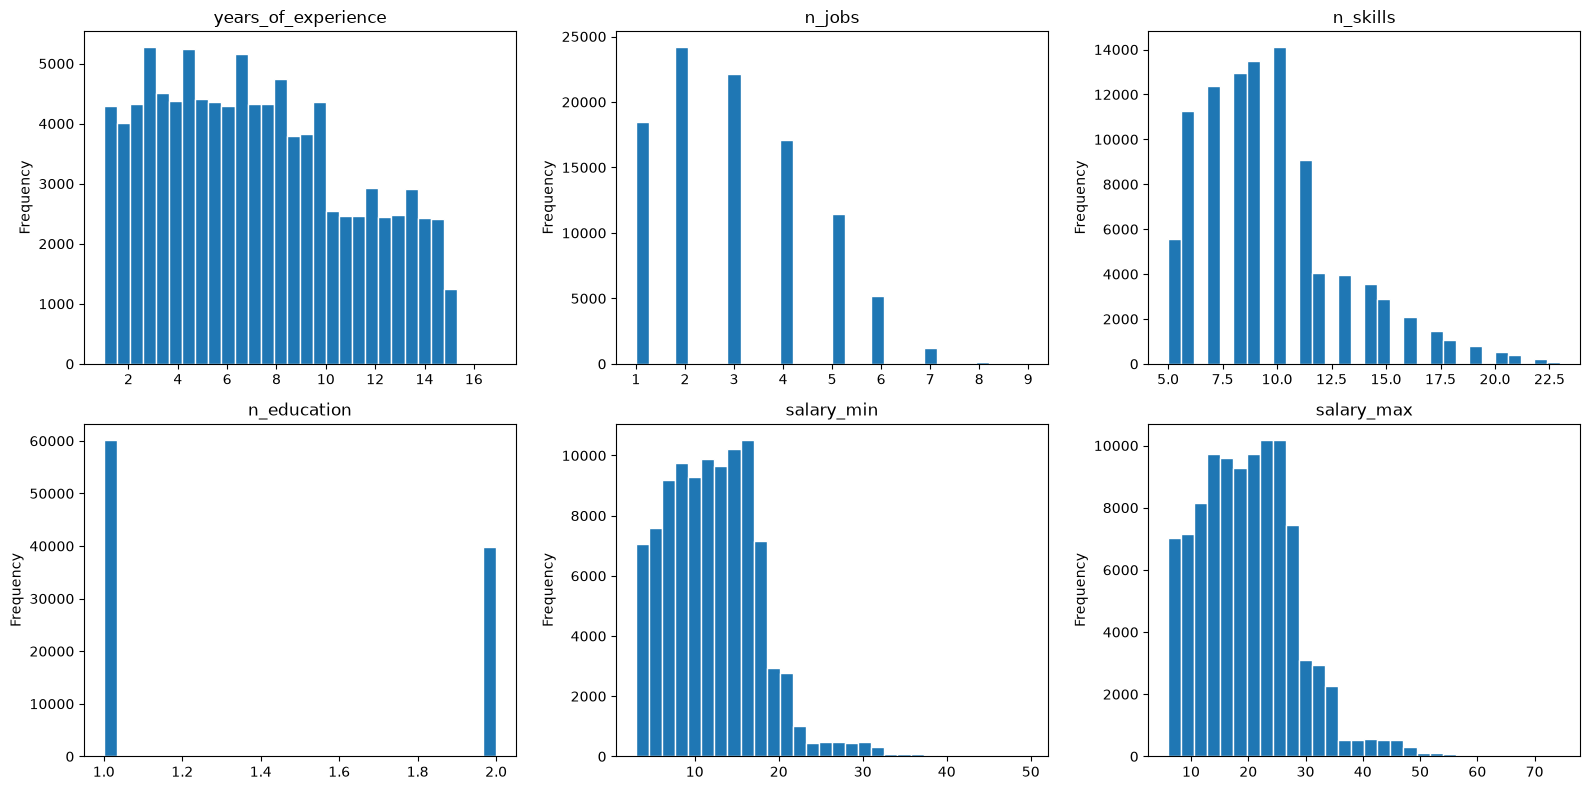

In [19]:
# Histograms for the headline numeric fields.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["years_of_experience", "n_jobs", "n_skills", "n_education", "salary_min", "salary_max"]):
    df[col].dropna().plot.hist(bins=30, ax=ax, title=col, edgecolor="white")
plt.tight_layout()
plt.show()

## 4. Redrob behavioral signals

These modulate fit by availability/engagement. The critical hazard is the **`-1` "no data" sentinel**: `github_activity_score` and `offer_acceptance_rate` use `-1` to mean *missing*, not *low*. From the `describe()` above both have a **median of -1** -- i.e. the signal is absent for the majority of candidates. Treating `-1` as a low score (or as 0) would systematically punish everyone with no GitHub / no offer history. So we (a) quantify the `-1` share per signal, (b) map `-1 -> NaN -> neutral`, and (c) demote any signal that is >40% missing to a weak tiebreaker at most.

In [20]:
# Quantify the -1 sentinel per numeric signal. Per the schema only github_activity_score
# and offer_acceptance_rate have a -1 floor, but we scan all numeric signals to be sure
# nothing else smuggles a sentinel in.
SENTINEL = -1
numeric_signal_cols = [
    "github_activity_score", "offer_acceptance_rate",
    "profile_completeness_score", "recruiter_response_rate", "interview_completion_rate",
    "avg_response_time_hours", "profile_views_received_30d", "applications_submitted_30d",
    "connection_count", "endorsements_received", "notice_period_days",
    "search_appearance_30d", "saved_by_recruiters_30d",
]
miss = pd.Series({c: (df[c] == SENTINEL).mean() for c in numeric_signal_cols}).sort_values(ascending=False)
guide = pd.DataFrame({"pct_minus1": (miss * 100).round(1)})
guide["weighting"] = np.where(
    miss > 0.40, "weak tiebreaker only",
    np.where(miss > 0.0, "usable; impute -1 -> neutral", "fully usable"),
)
print("Per-signal -1 (no-data) prevalence and recommended weighting:")
print(guide.to_string())

def neutralize(series, sentinel=SENTINEL):
    # Map the -1 sentinel to NaN so it can be imputed to a NEUTRAL value (e.g. the
    # population median of real values), never to 0. Use this everywhere these two
    # signals feed a score.
    return series.where(series != sentinel, np.nan)

print("\nNeutral fill values (median of non-sentinel values):")
for col in ["github_activity_score", "offer_acceptance_rate"]:
    print(f"  {col}: {neutralize(df[col]).median():.3f}")

Per-signal -1 (no-data) prevalence and recommended weighting:
                            pct_minus1             weighting
github_activity_score             64.6  weak tiebreaker only
offer_acceptance_rate             59.6  weak tiebreaker only
profile_completeness_score         0.0          fully usable
recruiter_response_rate            0.0          fully usable
interview_completion_rate          0.0          fully usable
avg_response_time_hours            0.0          fully usable
profile_views_received_30d         0.0          fully usable
applications_submitted_30d         0.0          fully usable
connection_count                   0.0          fully usable
endorsements_received              0.0          fully usable
notice_period_days                 0.0          fully usable
search_appearance_30d              0.0          fully usable
saved_by_recruiters_30d            0.0          fully usable

Neutral fill values (median of non-sentinel values):
  github_activity_score: 28.40

In [21]:
# Boolean / categorical signals.
print("Boolean / categorical signals:")
for c in ["open_to_work_flag", "willing_to_relocate", "verified_email", "verified_phone", "linkedin_connected", "preferred_work_mode"]:
    print(f"\n{c}:")
    print(df[c].value_counts(dropna=False))

Boolean / categorical signals:

open_to_work_flag:
open_to_work_flag
False    64661
True     35339
Name: count, dtype: int64

willing_to_relocate:
willing_to_relocate
False    71196
True     28804
Name: count, dtype: int64

verified_email:
verified_email
True     72003
False    27997
Name: count, dtype: int64

verified_phone:
verified_phone
True     61789
False    38211
Name: count, dtype: int64

linkedin_connected:
linkedin_connected
False    64001
True     35999
Name: count, dtype: int64

preferred_work_mode:
preferred_work_mode
hybrid      25076
onsite      25000
flexible    25000
remote      24924
Name: count, dtype: int64


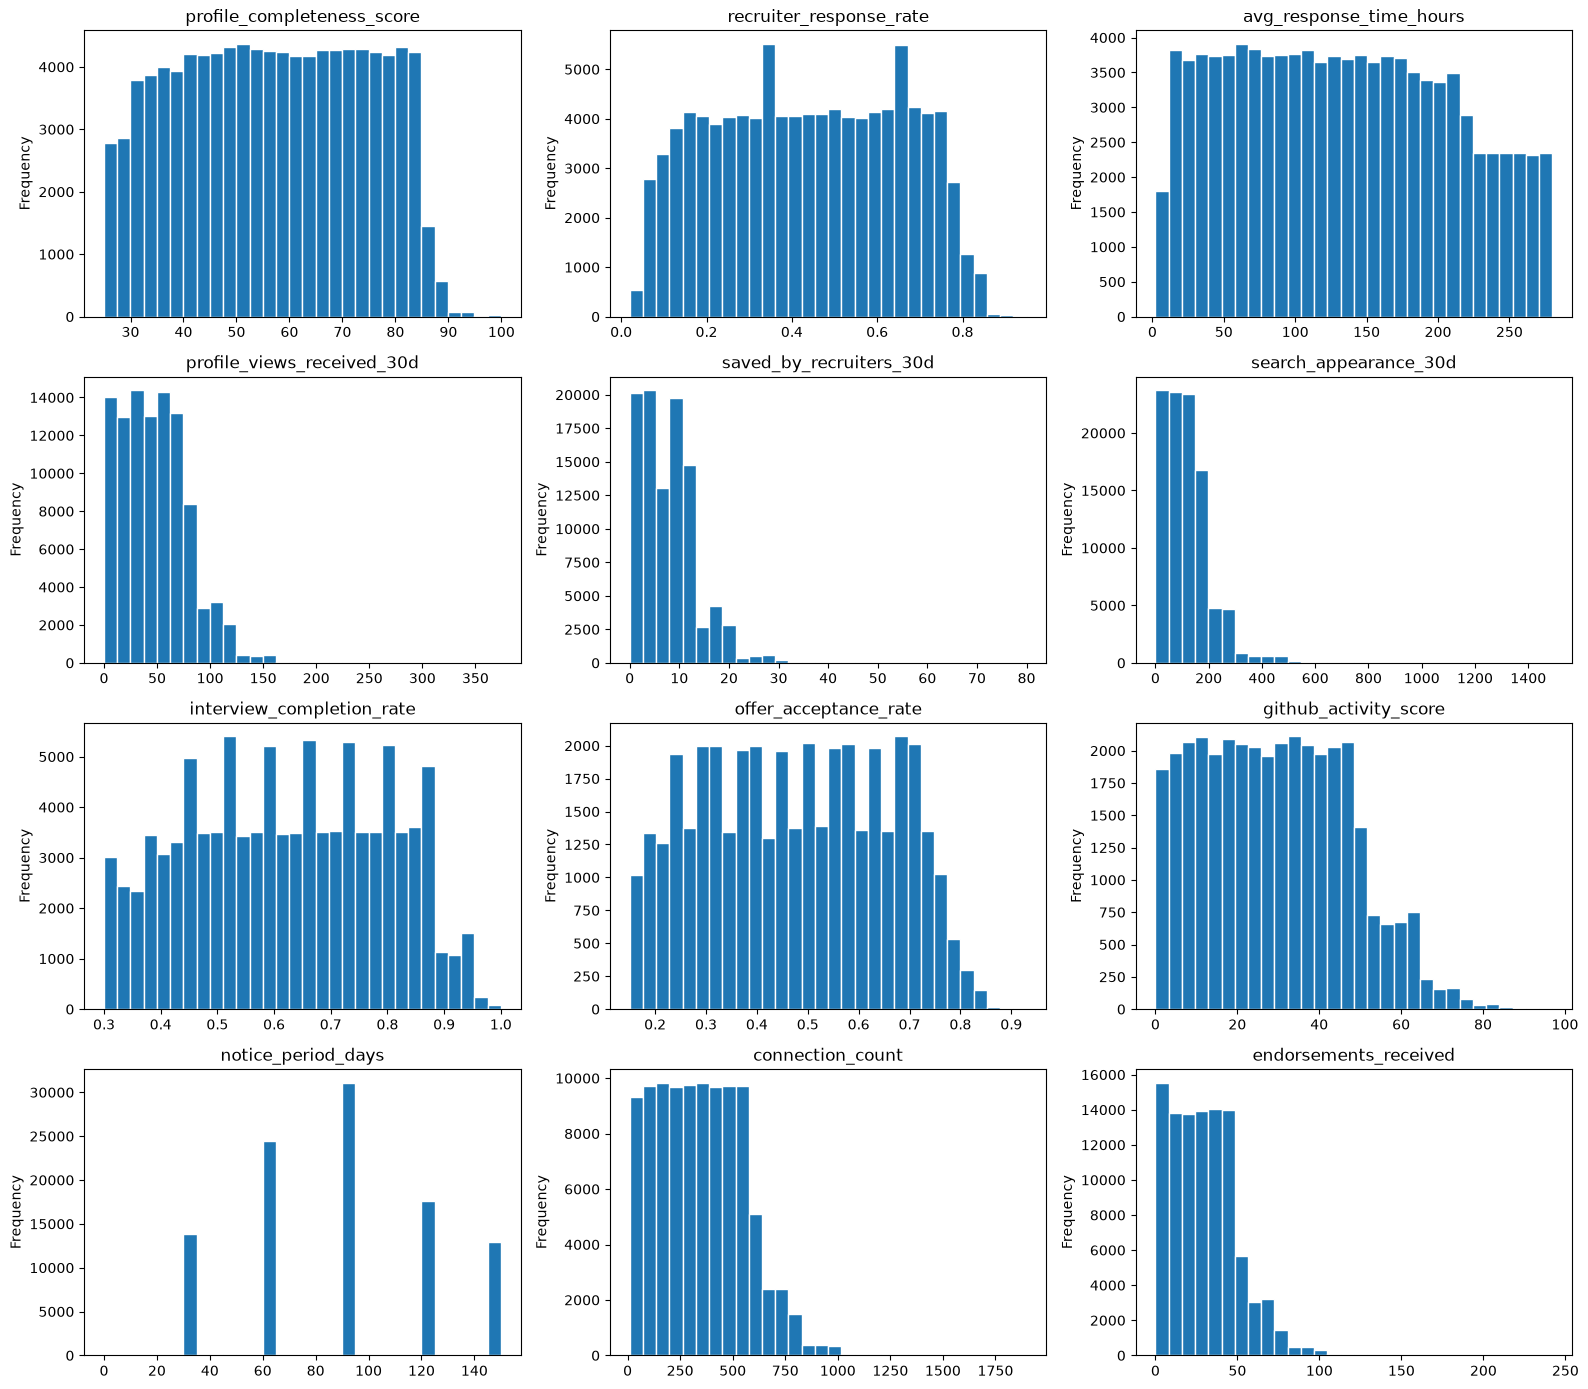

In [22]:
# Continuous signals, with the -1 sentinels neutralized so distributions aren't skewed.
cont = df.copy()
cont["github_activity_score"] = neutralize(cont["github_activity_score"])
cont["offer_acceptance_rate"] = neutralize(cont["offer_acceptance_rate"])

cont_cols = [
    "profile_completeness_score", "recruiter_response_rate", "avg_response_time_hours",
    "profile_views_received_30d", "saved_by_recruiters_30d", "search_appearance_30d",
    "interview_completion_rate", "offer_acceptance_rate", "github_activity_score",
    "notice_period_days", "connection_count", "endorsements_received",
]
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.ravel(), cont_cols):
    cont[col].dropna().plot.hist(bins=30, ax=ax, title=col, edgecolor="white")
plt.tight_layout()
plt.show()

count    100000.000000
mean        108.723890
std          66.588459
min           0.000000
25%          52.000000
50%         105.000000
75%         162.000000
max         240.000000
Name: days_since_active, dtype: float64

Inactive > 90 days: 56.8%
Inactive > 180 days: 17.2%


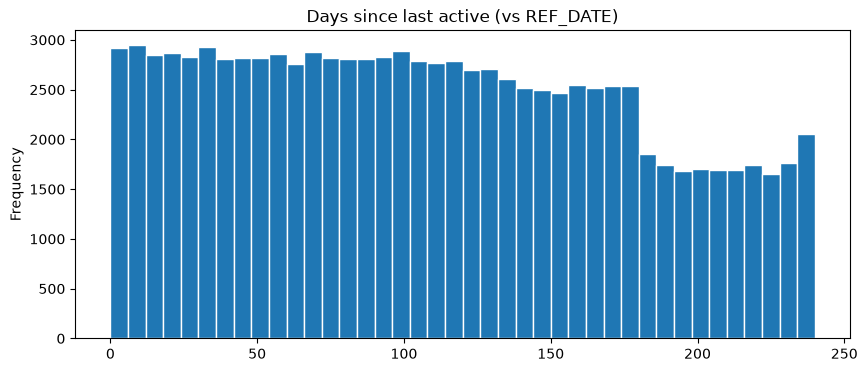

In [23]:
# Recency: days since last_active, anchored to REF_DATE (data-derived, deterministic).
# "Inactive for months" = effectively unavailable per the JD, regardless of paper fit.
last_active = pd.to_datetime(df["last_active_date"], errors="coerce")
df["days_since_active"] = (REF_DATE - last_active).dt.days
print(df["days_since_active"].describe())
print(f"\nInactive > 90 days: {(df['days_since_active'] > 90).mean():.1%}")
print(f"Inactive > 180 days: {(df['days_since_active'] > 180).mean():.1%}")
df["days_since_active"].dropna().plot.hist(bins=40, figsize=(10, 4), title="Days since last active (vs REF_DATE)", edgecolor="white")
plt.show()

## 5. Skills — title-vs-skills coherence, not keyword count

The JD warns explicitly: *"the right answer is not find candidates whose skills section contains the most AI keywords."* A raw count (`n_skills`, or even AI-keyword hits) is exactly the wrong signal -- it rewards stuffers. What separates a genuine fit from a stuffer is **quality and coherence**:

- a **stuffer** lists many AI skills with a non-technical title, no endorsements, and ~0 months used;
- a **genuine fit** has a technical title and AI skills that are endorsed and actually used for years.

So we keep the full skill objects (name + proficiency + endorsements + duration) and derive a quality-weighted `ai_depth`, a `trusted_ai` count, and an `is_stuffer` flag from the title/skill mismatch.

In [24]:
AI_KEYWORDS = {
    "machine learning", "deep learning", "nlp", "natural language processing",
    "embeddings", "retrieval", "rag", "vector search", "vector database",
    "information retrieval", "ranking", "recommender", "recommendation",
    "transformers", "llm", "fine-tuning", "lora", "pytorch", "tensorflow",
    "sentence-transformers", "faiss", "pinecone", "weaviate", "qdrant",
    "milvus", "elasticsearch", "opensearch", "bm25", "learning to rank",
    "xgboost", "semantic search", "bert", "gpt",
}
TECH_TITLE_RE = re.compile(
    r"engineer|scientist|\bml\b|machine learning|\bai\b|data scien|applied scien|research|developer|architect|\bnlp\b",
    re.I,
)
PROF_W = {"beginner": 0.25, "intermediate": 0.5, "advanced": 0.8, "expert": 1.0}

def is_ai_skill(name):
    n = (name or "").lower()
    return any(kw in n for kw in AI_KEYWORDS)

def skill_features(c):
    title = c.get("profile", {}).get("current_title") or ""
    title_tech = bool(TECH_TITLE_RE.search(title))
    skills = c.get("skills", []) or []
    ai = [s for s in skills if is_ai_skill(s.get("name"))]
    ai_hits = len(ai)
    # "Trusted" = actually used (>= 6 months) AND externally validated (>= 1 endorsement).
    trusted_ai = sum(
        1 for s in ai
        if (s.get("duration_months") or 0) >= 6 and (s.get("endorsements") or 0) >= 1
    )
    # Quality-weighted AI depth: proficiency * years-used (capped), only when endorsed.
    ai_depth = sum(
        PROF_W.get(s.get("proficiency"), 0) * min((s.get("duration_months") or 0) / 12.0, 5.0)
        for s in ai if (s.get("endorsements") or 0) >= 1
    )
    # Stuffer = lots of AI keywords, non-technical title, almost no trusted depth.
    is_stuffer = ai_hits >= 5 and not title_tech and trusted_ai <= 1
    return pd.Series({
        "title_tech": title_tech,
        "ai_hits": ai_hits,
        "trusted_ai": trusted_ai,
        "ai_depth": round(ai_depth, 2),
        "is_stuffer": is_stuffer,
    })

skills_df = pd.DataFrame(skill_features(c) for c in records)
df = pd.concat([df, skills_df], axis=1)
print(df[["ai_hits", "trusted_ai", "ai_depth"]].describe())
print("\nLikely keyword stuffers (>=5 AI skills, non-tech title, <=1 trusted):", int(df["is_stuffer"].sum()))
print("Technical title with real AI depth (ai_depth>=3 & title_tech):", int(((df["ai_depth"] >= 3) & df["title_tech"]).sum()))

             ai_hits    trusted_ai       ai_depth
count  100000.000000  100000.00000  100000.000000
mean        0.799320       0.64715       0.856828
std         2.008529       1.52212       2.173241
min         0.000000       0.00000       0.000000
25%         0.000000       0.00000       0.000000
50%         0.000000       0.00000       0.000000
75%         1.000000       1.00000       0.380000
max        13.000000      12.00000      49.650000

Likely keyword stuffers (>=5 AI skills, non-tech title, <=1 trusted): 22
Technical title with real AI depth (ai_depth>=3 & title_tech): 8546


In [25]:
# The trap, made concrete: AI keyword density does NOT imply a relevant title or real depth.
print("AI-keyword density vs. technical title:")
print(pd.crosstab((df["ai_hits"] >= 6).rename("high_ai_keywords"), df["title_tech"].rename("technical_title")))

cols = ["candidate_id", "current_title", "ai_hits", "trusted_ai", "ai_depth", "years_of_experience"]
print("\nKeyword stuffers (high AI keywords, non-technical title, no trusted depth):")
print(df[df["is_stuffer"]].sort_values("ai_hits", ascending=False)[cols].head(15).to_string(index=False))

print("\nContrast -- genuine fits (technical title + real, endorsed, used AI depth):")
print(df[(df["title_tech"]) & (df["ai_depth"] >= 4)].sort_values("ai_depth", ascending=False)[cols].head(10).to_string(index=False))

AI-keyword density vs. technical title:
technical_title   False  True 
high_ai_keywords              
False             53678  40574
True               4378   1370

Keyword stuffers (high AI keywords, non-technical title, no trusted depth):
candidate_id      current_title  ai_hits  trusted_ai  ai_depth  years_of_experience
CAND_0024737   Customer Support        8           1      1.04                  4.6
CAND_0058516   Graphic Designer        8           1      1.35                  9.9
CAND_0029929    Sales Executive        7           1      1.73                  9.7
CAND_0079407    Project Manager        7           1      1.47                  7.5
CAND_0046698   Graphic Designer        7           1      1.04                  7.0
CAND_0099494 Operations Manager        6           1      0.88                  1.6
CAND_0061193    Project Manager        6           1      1.27                 10.9
CAND_0017254     Content Writer        6           1      1.31                  2.5
CAN

## 6. Honeypots — a precision gate on your top ranks, not a pool-wide classifier

~80 candidates have *subtly impossible* profiles and are forced to relevance tier 0. **Honeypot rate > 10% in your top 100 = disqualification.**

The reframe that makes this tractable: **you do not need to find all ~80 honeypots in the pool.** A honeypot with an "Accountant" title and impossible internals was never going to reach your top 100, so it's harmless. The only honeypots that can disqualify you are the ones that *score high enough to land in your top 100*. So the detector belongs at the **end of the pipeline**, run on your top ~150, dropping anything that trips a flag, then taking the top 100:

```
scored = your_ranker(candidates)        # best-first
top    = scored[: 100 + BUFFER]         # e.g. BUFFER = 50
clean  = [cid for cid in top if not honeypot_reasons(by_id[cid])]
submission = clean[:100]
```

That means **precision at the top matters far more than pool-wide recall**, and it gives you margin. The detector below sticks to *high-precision impossibility checks* (experience vs. summed history, single-tenure vs. YoE, expert skills with 0 months used) plus cheap career/education **date-integrity guards** that fire zero false positives on this pool. It deliberately drops looser heuristics (e.g. "skill used longer than the career") that over-fire on legitimate candidates — at the gate, a false positive costs you a real top-100 slot.

In [26]:
def honeypot_reasons(c, ref_date=REF_DATE):
    # Return a list of "this cannot be true" reasons; empty list = passes the gate.
    # These are impossibility checks, NOT weak-candidate signals -- a strong-LOOKING
    # profile (good title, plausible YoE, right skills) is exactly what must still be screened.
    reasons = []
    p = c.get("profile", {})
    hist = c.get("career_history", []) or []
    skills = c.get("skills", []) or []
    edu = c.get("education", []) or []
    yoe = p.get("years_of_experience") or 0
    total_months = sum((h.get("duration_months") or 0) for h in hist)
    max_tenure = max((h.get("duration_months") or 0) for h in hist) if hist else 0

    # --- experience vs career history ---
    if yoe - total_months / 12.0 > 3:
        reasons.append("yoe_exceeds_summed_history")
    if yoe and max_tenure / 12.0 > yoe + 1:
        reasons.append("single_tenure_exceeds_yoe")

    # --- career-date integrity (catches well-disguised honeypots) ---
    starts = []
    for h in hist:
        sd, ed = h.get("start_date"), h.get("end_date")
        try:
            d0 = datetime.fromisoformat(sd).date() if sd else None
            d1 = datetime.fromisoformat(ed).date() if ed else None
        except ValueError:
            d0 = d1 = None
        if d0:
            starts.append(d0)
            if d0 > ref_date.date():
                reasons.append("job_starts_in_future")
        if d0 and d1:
            if d1 < d0:
                reasons.append("job_end_before_start")
            span_months = (d1 - d0).days / 30.44
            if abs(span_months - (h.get("duration_months") or 0)) > 24:
                reasons.append("duration_contradicts_dates")
    if starts:
        career_span_yrs = (ref_date.date() - min(starts)).days / 365.25
        if yoe - career_span_yrs > 4:
            reasons.append("yoe_predates_first_job")

    # --- skills that can't be real ---
    expert_zero = sum(1 for s in skills if s.get("proficiency") == "expert" and (s.get("duration_months") or 0) == 0)
    if expert_zero >= 3:
        reasons.append("expert_skills_zero_duration")
    # NB: "skill duration > career length" is NOT used -- in this synthetic data skill
    # durations routinely exceed professional YoE (school/hobby time), so it fires on ~9%
    # of the pool and would drop genuine candidates at the gate. Keep the gate high-precision.

    # --- education-date integrity ---
    for e in edu:
        sy, ey = e.get("start_year"), e.get("end_year")
        if sy and ey and ey < sy:
            reasons.append("education_end_before_start")
        if ey and ey > ref_date.year + 1:
            reasons.append("education_graduates_in_future")

    return sorted(set(reasons))

df["honeypot_suspect"] = [bool(honeypot_reasons(c)) for c in records]
print(f"Flagged as impossible (full pool): {int(df['honeypot_suspect'].sum())} / {len(df)}")
print("\nReason frequency:")
reason_counts = Counter(r for c in records for r in honeypot_reasons(c))
for r, n in reason_counts.most_common():
    print(f"  {n:5d}  {r}")

Flagged as impossible (full pool): 66 / 100000

Reason frequency:
     25  yoe_exceeds_summed_history
     25  yoe_predates_first_job
     21  expert_skills_zero_duration
     20  single_tenure_exceeds_yoe


In [27]:
# The GATE itself -- the mechanism that actually protects the submission.
def apply_honeypot_gate(ranked_ids, k=100, buffer=50):
    # ranked_ids: candidate_ids best-first from your scorer. Take a buffer beyond k,
    # drop any that trip the impossibility detector, keep the first k clean ones.
    clean = [cid for cid in ranked_ids[: k + buffer] if not honeypot_reasons(by_id[cid])]
    return clean[:k]

# Sanity-check the detector against the ONLY honeypots that matter: those that also look
# like strong AI fits (technical title + real AI depth) and could sneak into a top 100.
dangerous = df[(df["title_tech"]) & (df["ai_depth"] >= 2) & (df["honeypot_suspect"])]
print(f"Impossible profiles that ALSO look like strong AI fits: {len(dangerous)}")
cols = ["candidate_id", "current_title", "years_of_experience", "ai_depth"]
print(dangerous.sort_values("ai_depth", ascending=False)[cols].head(15).to_string(index=False))
print("\nWhy each is flagged:")
for cid in dangerous.sort_values("ai_depth", ascending=False)["candidate_id"].head(6):
    print(f"  {cid}: {honeypot_reasons(by_id[cid])}")

Impossible profiles that ALSO look like strong AI fits: 15
candidate_id                   current_title  years_of_experience  ai_depth
CAND_0039754        Senior Applied Scientist                 16.2     47.12
CAND_0013536             Applied ML Engineer                 14.1     35.65
CAND_0095619                    NLP Engineer                 15.6     35.60
CAND_0055992                     AI Engineer                 16.9     34.70
CAND_0071115 Recommendation Systems Engineer                 16.5     25.00
CAND_0037000                 Search Engineer                  2.7     24.80
CAND_0010770 Recommendation Systems Engineer                 15.2     21.98
CAND_0093331                    NLP Engineer                 16.1     17.93
CAND_0091534                     AI Engineer                 16.6     11.07
CAND_0095140                Backend Engineer                  5.0      9.93
CAND_0066405                  Cloud Engineer                 12.3      3.33
CAND_0070429               So

## 7. Drill into individual candidates

Pretty-print full records to validate the heuristics above against real profiles. Swap the `candidate_id` to inspect anyone flagged as a stuffer or honeypot.

In [28]:
def show(cid):
    print(json.dumps(by_id[cid], indent=2, ensure_ascii=False))

# Example: inspect the first record.
show(records[0]["candidate_id"])

{
  "candidate_id": "CAND_0000001",
  "profile": {
    "anonymized_name": "Ira Vora",
    "headline": "Backend Engineer | SQL, Spark, Cloud",
    "summary": "Software / data professional with 6.9 years of experience building data pipelines, backend systems, and analytics infrastructure. I'm a backend/data hybrid — Spark, Airflow, SQL warehouses are home territory; I'm building competence on the ML side. My toolkit is solid on the data engineering side — Python, SQL, Spark, Airflow, warehouse design — and I've completed a couple of self-directed ML projects (Kaggle competitions, side projects fine-tuning small models). Interested in transitioning toward more AI/ML-focused work, ideally at a company where I can leverage my existing data-infra skills while learning modern ML practice.",
    "location": "Toronto",
    "country": "Canada",
    "years_of_experience": 6.9,
    "current_title": "Backend Engineer",
    "current_company": "Mindtree",
    "current_company_size": "10001+",
    "cu

## 8. Takeaways for the ranker

Confirmed against the data above; carry these into `rank.py`:

- **Score on coherence, not keyword count.** `ai_depth` (proficiency x years-used, endorsed) and the `title_tech` x AI-skills interaction separate genuine fits from stuffers; raw `n_skills` / keyword hits reward the trap.
- **Behavioral signals gate availability, with `-1` handled correctly.** Down-weight long-inactive candidates (`days_since_active`) and low `recruiter_response_rate`. `github_activity_score` and `offer_acceptance_rate` are >40% `-1` -> map `-1` to neutral and use them only as weak tiebreakers; never let `-1` read as 0.
- **JD intent over JD keywords.** Product-company recommender/search experience counts even without the words "RAG"/"Pinecone"; consulting-only or pure-research-only careers are explicit anti-signals.
- **Honeypots: gate at the end, don't classify the pool.** Score first, take top ~150, drop anything `honeypot_reasons()` flags, then take 100 (`apply_honeypot_gate`). Precision on high-scoring candidates is what keeps honeypot rate < 10%.
- **Determinism is mandatory.** Everything time-based is anchored to `REF_DATE = max(last_active_date)`. Same input -> same CSV, which the Stage-3 reproduction requires.